# 1. Loading the Datasets
## 1.1 Load both datasets from scikit-learn

In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer()

## 1.2 Create the data frames

In [2]:
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, index=X.index, name="target")

In [3]:
print("First five rows")
display(X.head())

print("Dataset Shape:", X.shape)
print("Features Names:", X.columns.tolist())

class_count = y.value_counts().sort_index()

class_overview = pd.DataFrame({
    "target_label": class_count.index,
    "target_name": [dataset.target_names[label] for label in class_count.index],
    "sample_count": class_count.to_numpy(),
})

print("Target labels, class names, and sample counts")
display(class_overview)

First five rows


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset Shape: (569, 30)
Features Names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target labels, class names, and sample counts


,target_label,target_name,sample_count
0,0,malignant,212
1,1,benign,357


## Dataset overview

The dataset contains 569 samples and 30 measurement features. The target labels
correspond to 0 = malignant and 1 = benign.
Benign samples make up the majority, accounting for approximately 63%.

# 2. Dataset Quality Checks
## 2.1 Missing Values and Duplicates

In [4]:
data_for_checks = X.assign(target=y)

missing_counts = data_for_checks.isna().sum()
display(missing_counts.rename("missing_count").to_frame())

duplicate_count = data_for_checks.duplicated().sum()
print("Duplicate rows:", duplicate_count)

,missing_count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Duplicate rows: 0


The number of missing values ​​in all columns is zero. There are no duplicate rows.

## 2.2 Potential Outliers

In [5]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outside_bounds = X.lt(lower_bound) | X.gt(upper_bound)
outlier_counts = outside_bounds.sum().sort_values(ascending=False)

display(outlier_counts.rename("potential_outlier_count").to_frame())

,potential_outlier_count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
compactness error,28
fractal dimension error,28
symmetry error,27
mean area,25
worst fractal dimension,24


According to the IQR method, the highest number of potential outliers was observed in the 'area error' feature (65). While 38 values ​​fell outside the limits for both 'radius error' and 'perimeter error', no outliers were found for the 'worst concave points' feature.

These values are flagged only as *potential* outliers; they are not deleted or clipped, because large tumours are a genuine part of the data rather than measurement errors. They can still affect the algorithms:

- **KNN and K-Means** use Euclidean distances, so a few very large values (especially in features measured on a large scale, such as `area error` or `worst area`) can dominate the distance and pull cluster centroids towards them.
- **StandardScaler** uses the training mean and standard deviation, which are both sensitive to extreme values, so outliers also influence the scaled representation.
- **Gaussian Naive Bayes** estimates a mean and variance per class; extreme values inflate the variance estimates.
- **Decision Trees** split on thresholds, so they are relatively robust to extreme values.

## 2.3 Data Types

In [6]:
display(X.dtypes.rename("dtype").to_frame())

numeric_count = X.select_dtypes(include="number").shape[1]
categorical_count = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).shape[1]

print("Numerical features:", numeric_count)
print("Categorical features:", categorical_count)

,dtype
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


Numerical features: 30
Categorical features: 0


All 30 features in the Breast Cancer dataset are of type float64 and are numerical.

# 3. Exploratory Data Analysis (EDA)

## 3.1 Descriptive statistics

In [7]:
statistics = X.describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
].rename(columns={"25%": "Q1", "50%": "median", "75%": "Q3"})

display(statistics.round(3))

,mean,std,min,Q1,median,Q3,max
mean radius,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,0.063,0.007,0.050,0.058,0.062,0.066,0.097


The mean of area error is 40.337, while its median is 24.530. This suggests that larger values pull the mean upward.

## 3.2 Class distribution and correlations

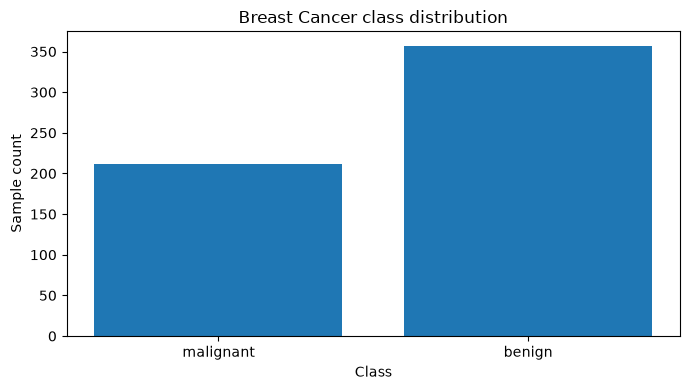

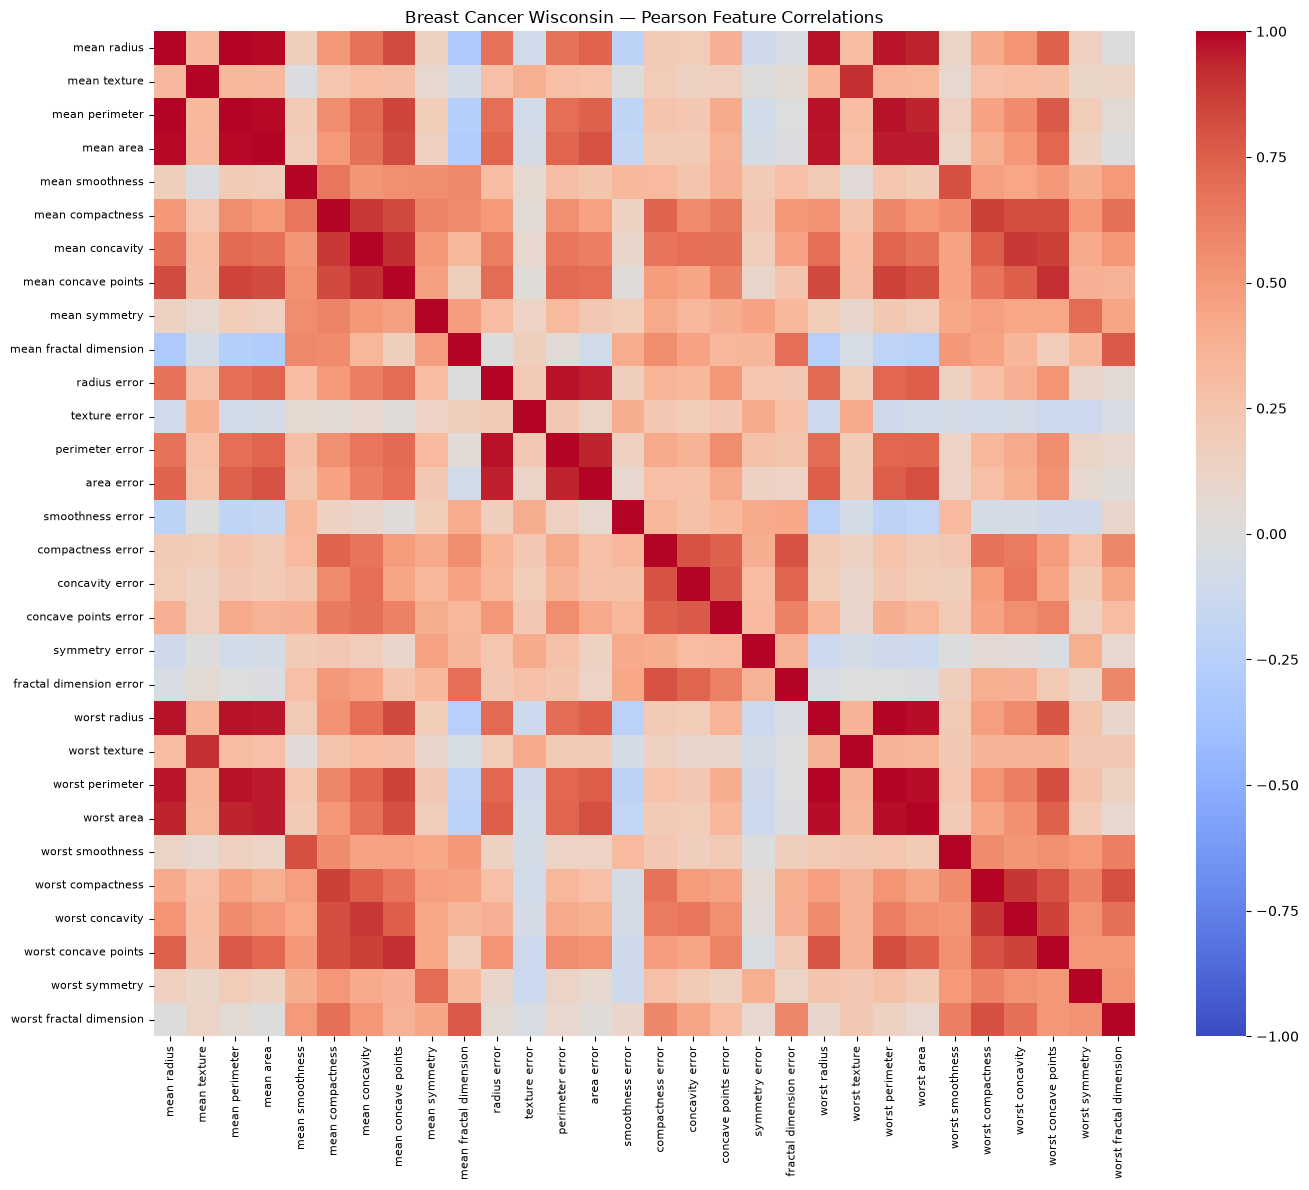

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

figure_dir = Path("figures/breast_cancer")
figure_dir.mkdir(parents=True, exist_ok=True)

class_counts = y.value_counts().sort_index()
class_names = [dataset.target_names[label] for label in class_counts.index]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_names, class_counts.to_numpy())
ax.set(title="Breast Cancer class distribution", xlabel="Class", ylabel="Sample count")
fig.tight_layout()
fig.savefig(figure_dir / "class_distribution.png", dpi=150)
plt.show()

correlations = X.corr(method="pearson")

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    correlations,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=True,
    yticklabels=True,
    ax=ax,
)

ax.set_title("Breast Cancer Wisconsin — Pearson Feature Correlations")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelrotation=0, labelsize=8)

fig.tight_layout()
fig.savefig(figure_dir / "correlation_heatmap.png", dpi=150)
plt.show()

In [9]:
import numpy as np
import pandas as pd

row_indices, col_indices = np.triu_indices(len(correlations), k=1)

correlation_pairs = pd.DataFrame({
    "feature_1": correlations.index[row_indices],
    "feature_2": correlations.columns[col_indices],
    "pearson_r": correlations.to_numpy()[row_indices, col_indices],
})

correlation_pairs["absolute_r"] = correlation_pairs["pearson_r"].abs()
top_three_pairs = correlation_pairs.nlargest(3, "absolute_r")

display(top_three_pairs.reset_index(drop=True).round(3))

,feature_1,feature_2,pearson_r,absolute_r
0,mean radius,mean perimeter,0.998,0.998
1,worst radius,worst perimeter,0.994,0.994
2,mean radius,mean area,0.987,0.987


**Interpretation (3.2).** The class distribution is moderately imbalanced: 357 benign (≈63%) versus 212 malignant (≈37%) samples. This is why macro-averaged metrics and stratified splits are used later.

The three strongest unique feature pairs (diagonal and mirrored pairs excluded) are:

1. `mean radius` – `mean perimeter` (r = 0.998)
2. `worst radius` – `worst perimeter` (r = 0.994)
3. `mean radius` – `mean area` (r = 0.987)

All three are size measurements of the same cell nuclei. Perimeter grows proportionally with radius and area grows with the square of radius, so these correlations are expected geometrically. They indicate strong redundancy between features.

## 3.3 Boxplots

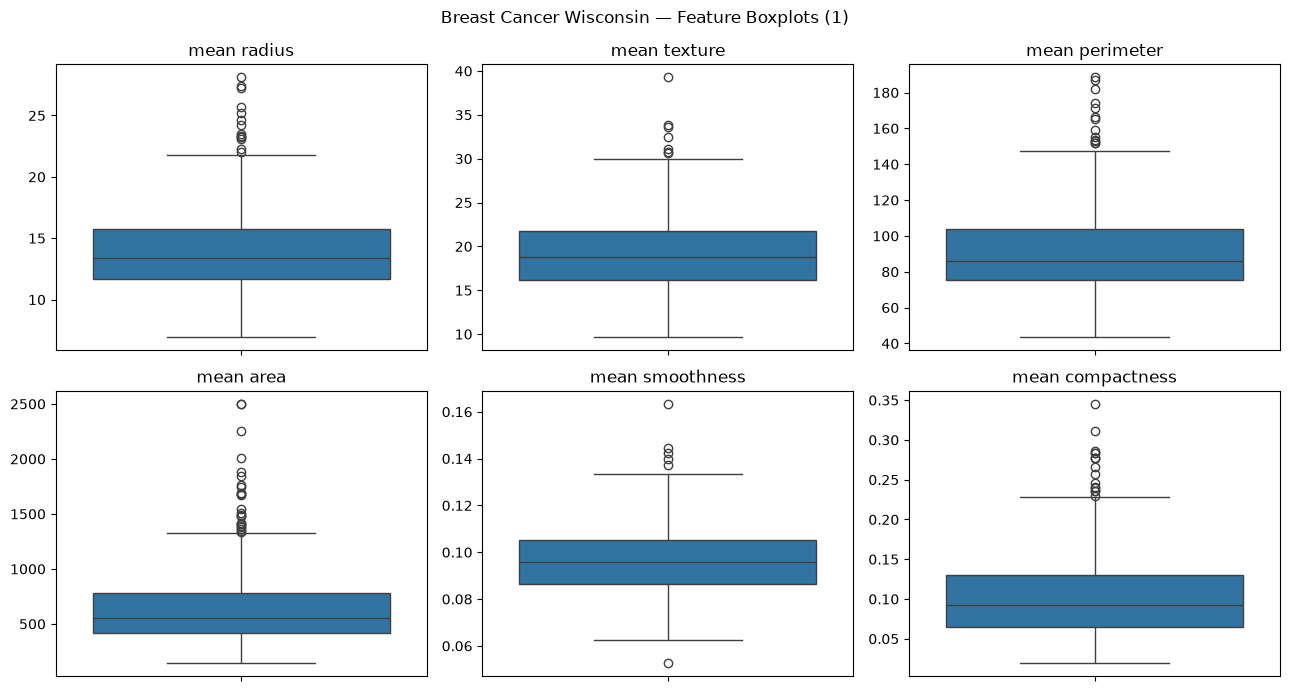

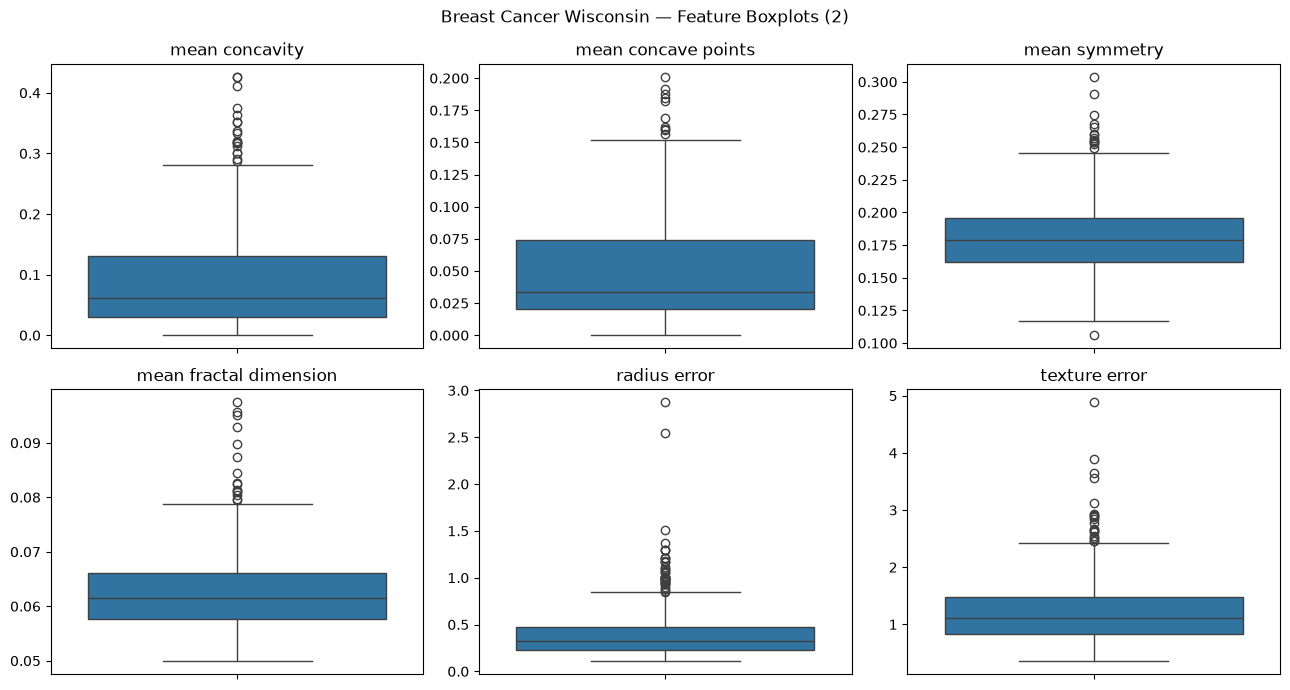

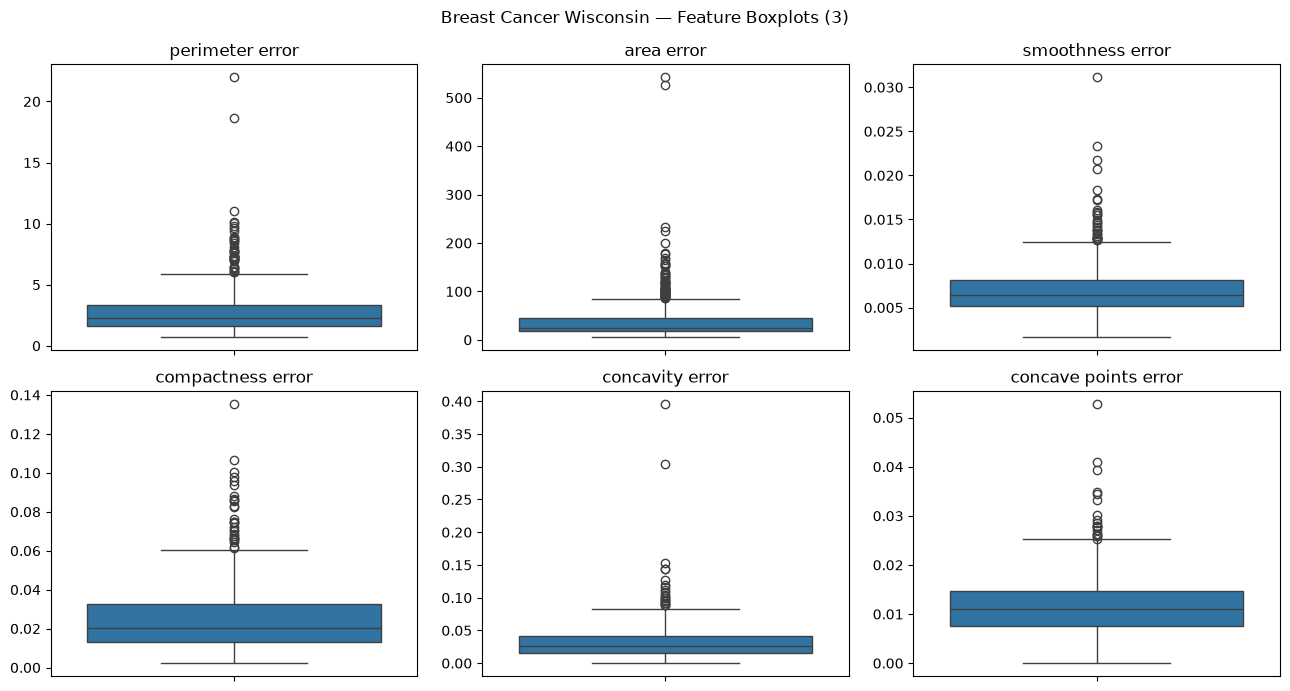

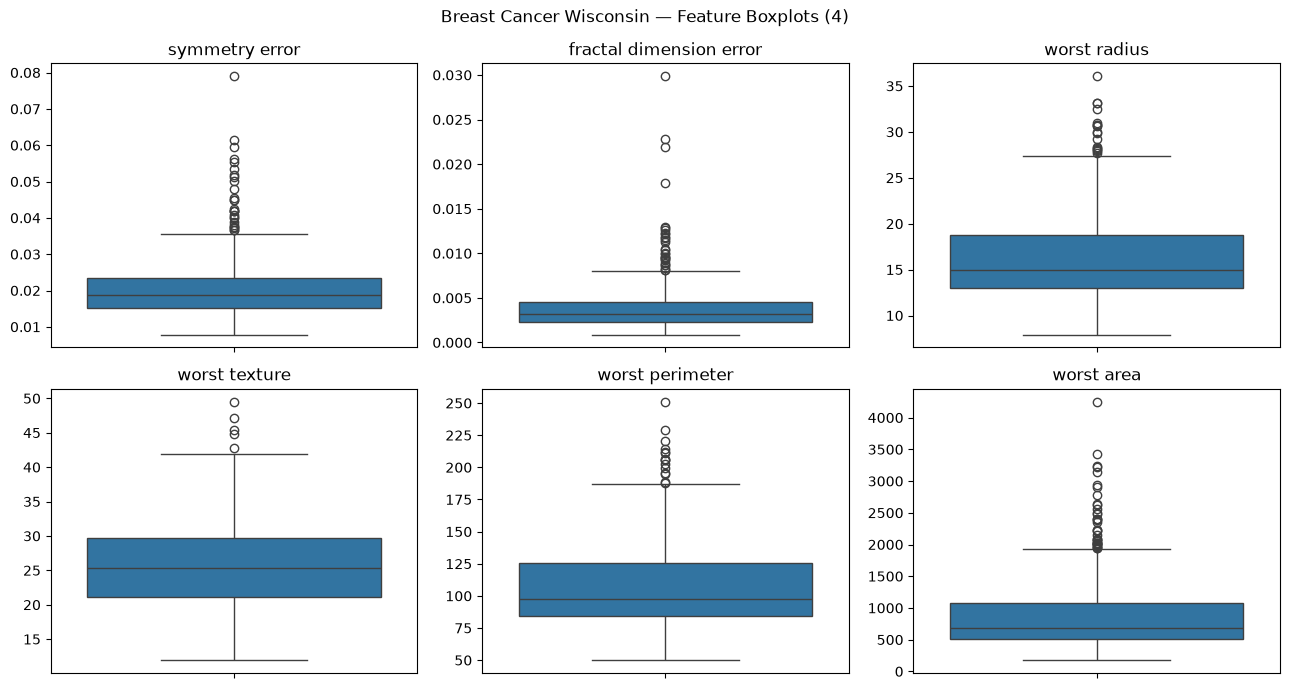

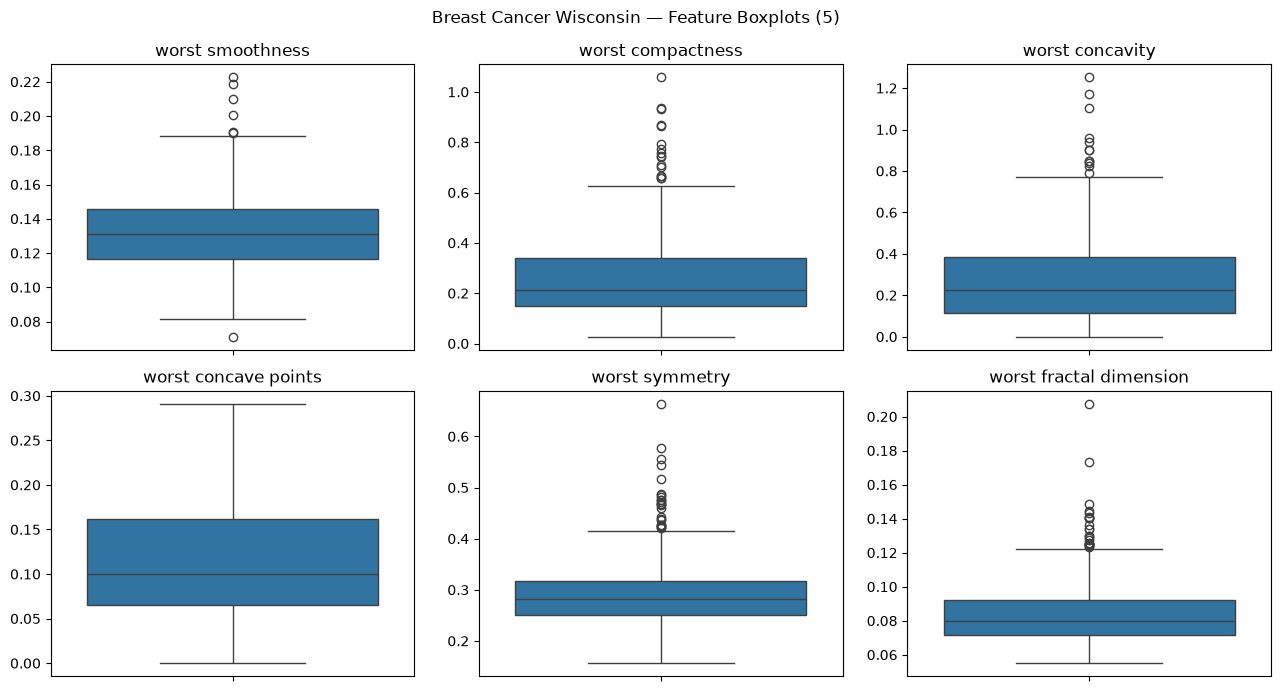

In [10]:
features_per_figure = 6

for start in range(0, X.shape[1], features_per_figure):
    features = X.columns[start:start + features_per_figure]
    group_number = start // features_per_figure + 1

    fig, axes = plt.subplots(2, 3, figsize=(13, 7))

    for ax, feature in zip(axes.flat, features):
        sns.boxplot(y=X[feature], ax=ax)
        ax.set_title(feature)
        ax.set_ylabel("")

    for ax in axes.flat[len(features):]:
        ax.set_visible(False)

    fig.suptitle(f"Breast Cancer Wisconsin — Feature Boxplots ({group_number})")
    fig.tight_layout()
    fig.savefig(figure_dir / f"boxplots_{group_number}.png", dpi=150)
    plt.show()

**Interpretation (3.3).**

- **Very different feature ranges:** area features are measured in hundreds to thousands (e.g. `mean area` reaches about 2,500), while smoothness, symmetry and fractal-dimension features stay below about 0.4. Without scaling, area features would dominate Euclidean distances in KNN and K-Means.
- **Right-skewed "error" features:** the standard-error features (for example `area error`, `radius error` and `perimeter error`) have long upper tails and many points beyond the upper whisker. This matches the IQR results in Section 2.2 and the large gap between the mean and median of `area error`.

# 4. Splitting the Datasets
## 4.1 Fix the test set and repeat the training/validation split

The 20% test set is reserved **once** with `random_state=42`. For each seed in `SEEDS = [42, 52, 62]` the remaining 80% is split into training and validation with `test_size=0.125` (0.125 × 80% = 10% of the full dataset). Pandas row indices are preserved, so every subset keeps the original row numbers.

In [11]:
from pathlib import Path
from sklearn.model_selection import train_test_split

DATASET_NAME = "breast_cancer"
SEEDS = [42, 52, 62]
TEST_SEED = 42
results_dir = Path("result")
results_dir.mkdir(parents=True, exist_ok=True)

X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=TEST_SEED
)
splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=seed
    )
    splits[seed] = {
        "X_train": X_train, "X_val": X_val,
        "y_train": y_train, "y_val": y_val,
    }

print("Fixed test set size:", len(X_test))
for seed in SEEDS:
    print(f"Seed {seed}: train={len(splits[seed]['X_train'])}, val={len(splits[seed]['X_val'])}")

Fixed test set size: 114
Seed 42: train=398, val=57
Seed 52: train=398, val=57
Seed 62: train=398, val=57


## 4.2 Verify the split

In [12]:
class_labels = sorted(y.unique())
summary_rows = []

for seed in SEEDS:
    subsets = {
        "train": splits[seed]["y_train"],
        "validation": splits[seed]["y_val"],
        "test": y_test,
    }
    for subset_name, subset_y in subsets.items():
        row = {
            "seed": seed,
            "subset": subset_name,
            "n_samples": len(subset_y),
            "percent_of_full": round(len(subset_y) / len(y) * 100, 2),
        }
        for label in class_labels:
            row[f"class_{label}_{dataset.target_names[label]}"] = int((subset_y == label).sum())
        summary_rows.append(row)

split_summary = pd.DataFrame(summary_rows)
print("Breast Cancer Wisconsin — split summary (3 subsets x 3 seeds)")
display(split_summary)

Breast Cancer Wisconsin — split summary (3 subsets x 3 seeds)


,seed,subset,n_samples,percent_of_full,class_0_malignant,class_1_benign
0,42,train,398,69.95,149,249
1,42,validation,57,10.02,21,36
2,42,test,114,20.04,42,72
3,52,train,398,69.95,149,249
4,52,validation,57,10.02,21,36
5,52,test,114,20.04,42,72
6,62,train,398,69.95,149,249
7,62,validation,57,10.02,21,36
8,62,test,114,20.04,42,72


In [13]:
test_index = set(X_test.index)
check_rows = []
for seed in SEEDS:
    train_index = set(splits[seed]["X_train"].index)
    val_index = set(splits[seed]["X_val"].index)
    check_rows.append({
        "seed": seed,
        "train∩val": len(train_index & val_index),
        "train∩test": len(train_index & test_index),
        "val∩test": len(val_index & test_index),
        "total_count": len(train_index) + len(val_index) + len(test_index),
        "equals_full_dataset": len(train_index | val_index | test_index) == len(X),
        "same_test_indices": set(y_test.index) == test_index,
    })
    assert len(train_index & val_index) == 0 and len(train_index & test_index) == 0 and len(val_index & test_index) == 0
    assert train_index | val_index | test_index == set(X.index)

display(pd.DataFrame(check_rows))

index_rows = []
for seed in SEEDS:
    for subset_name, subset_X in [("train", splits[seed]["X_train"]),
                                  ("validation", splits[seed]["X_val"]),
                                  ("test", X_test)]:
        index_rows += [{"dataset": DATASET_NAME, "seed": seed, "subset": subset_name, "row_index": int(i)}
                       for i in subset_X.index]
split_indices = pd.DataFrame(index_rows)
split_indices.to_csv(results_dir / f"{DATASET_NAME}_split_indices.csv", index=False)

print("First 10 test row indices:", sorted(X_test.index)[:10])
for seed in SEEDS:
    print(f"Seed {seed} — first 10 validation row indices:", sorted(splits[seed]["X_val"].index)[:10])

,seed,train∩val,train∩test,val∩test,total_count,equals_full_dataset,same_test_indices
0,42,0,0,0,569,True,True
1,52,0,0,0,569,True,True
2,62,0,0,0,569,True,True


First 10 test row indices: [1, 14, 20, 23, 24, 41, 51, 64, 70, 73]
Seed 42 — first 10 validation row indices: [7, 13, 15, 27, 38, 39, 49, 50, 60, 66]
Seed 52 — first 10 validation row indices: [13, 82, 87, 90, 98, 99, 111, 113, 123, 124]
Seed 62 — first 10 validation row indices: [26, 31, 33, 34, 36, 55, 61, 71, 72, 96]


**Interpretation (4).** Out of 569 samples, 398 are used for training, 57 for validation and 114 for testing in every repetition. Stratification keeps the class proportions almost identical across subsets (149 malignant / 249 benign in training, 21 / 36 in validation and 42 / 72 in test). The three seeds change only which samples are used for training versus validation.

# 5. Data Preprocessing and Scaling
## 5.1 Handle missing values, if present

In [14]:
total_missing = int(X.isna().sum().sum())
print("Total missing values in the dataset:", total_missing)
if total_missing == 0:
    print("No missing values exist, so no imputation step is added.")

Total missing values in the dataset: 0
No missing values exist, so no imputation step is added.


## 5.2 Select one scaler
**StandardScaler** is selected before running the experiments and is used for both datasets and all three seeds.

## 5.3 Fit and apply the scaler correctly

In [15]:
from sklearn.preprocessing import StandardScaler

scalers = {}
for seed in SEEDS:
    scaler = StandardScaler()
    scaler.fit(splits[seed]["X_train"])
    scalers[seed] = scaler

    splits[seed]["X_train_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_train"]),
        index=splits[seed]["X_train"].index, columns=X.columns,
    )
    splits[seed]["X_val_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_val"]),
        index=splits[seed]["X_val"].index, columns=X.columns,
    )
    
X_test_scaled = pd.DataFrame(
    scalers[TEST_SEED].transform(X_test), index=X_test.index, columns=X.columns
)

print("Fitted scalers:", list(scalers.keys()))

Fitted scalers: [42, 52, 62]


In [16]:
print("Breast Cancer Wisconsin — seed 42 training data BEFORE scaling")
display(splits[TEST_SEED]["X_train"].head().round(3))

print("Breast Cancer Wisconsin — seed 42 training data AFTER StandardScaler")
display(splits[TEST_SEED]["X_train_scaled"].head().round(3))

scaled_check = pd.DataFrame({
    "train_mean_after": splits[TEST_SEED]["X_train_scaled"].mean(),
    "train_std_after": splits[TEST_SEED]["X_train_scaled"].std(ddof=0),
}).round(3)
print("Mean and standard deviation of scaled seed-42 training features (first 5 features)")
display(scaled_check.head())

Breast Cancer Wisconsin — seed 42 training data BEFORE scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.085,0.101,0.068,0.031,0.178,0.062,...,13.46,23.07,88.13,551.3,0.105,0.216,0.190,0.076,0.268,0.078
390,10.26,12.22,65.75,321.6,0.100,0.075,0.019,0.020,0.180,0.066,...,11.38,15.65,73.23,394.5,0.134,0.165,0.086,0.067,0.294,0.077
420,11.57,19.04,74.20,409.7,0.085,0.077,0.055,0.014,0.203,0.063,...,13.07,26.98,86.43,520.5,0.125,0.194,0.256,0.067,0.304,0.083
356,13.05,18.59,85.09,512.0,0.108,0.130,0.096,0.056,0.204,0.065,...,14.19,24.85,94.22,591.2,0.134,0.266,0.257,0.126,0.311,0.083
446,17.75,28.03,117.30,981.6,0.100,0.131,0.170,0.083,0.171,0.059,...,21.53,38.54,145.40,1437.0,0.140,0.376,0.640,0.197,0.297,0.091


Breast Cancer Wisconsin — seed 42 training data AFTER StandardScaler


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.465,0.177,-0.468,-0.519,-0.884,-0.073,-0.281,-0.467,-0.077,-0.069,...,-0.573,-0.379,-0.561,-0.578,-1.226,-0.259,-0.416,-0.585,-0.340,-0.358
390,-1.084,-1.553,-1.065,-0.944,0.251,-0.554,-0.869,-0.753,-0.010,0.375,...,-1.001,-1.547,-1.000,-0.855,0.070,-0.573,-0.893,-0.724,0.046,-0.381
420,-0.715,-0.015,-0.721,-0.694,-0.814,-0.521,-0.442,-0.889,0.806,-0.044,...,-0.654,0.237,-0.611,-0.633,-0.346,-0.396,-0.117,-0.728,0.196,-0.074
356,-0.299,-0.116,-0.278,-0.403,0.855,0.463,0.052,0.166,0.821,0.281,...,-0.423,-0.099,-0.382,-0.508,0.070,0.049,-0.111,0.155,0.315,-0.055
446,1.024,2.013,1.034,0.933,0.251,0.482,0.936,0.846,-0.317,-0.532,...,1.086,2.057,1.128,0.984,0.327,0.731,1.638,1.218,0.100,0.359


Mean and standard deviation of scaled seed-42 training features (first 5 features)


,train_mean_after,train_std_after
mean radius,-0.0,1.0
mean texture,-0.0,1.0
mean perimeter,0.0,1.0
mean area,0.0,1.0
mean smoothness,0.0,1.0


**Interpretation (5).** There are no missing values, so no imputer is used. Validation subsets are transformed with the scaler of the same seed, and the fixed test set is transformed only with the seed-42 scaler. After scaling, the seed-42 training features have mean 0 and standard deviation 1. 

# 6. Preparing the Two Data Representations

In [17]:
representations = {}
for seed in SEEDS:
    representations[seed] = {
        "unscaled": {"X_train": splits[seed]["X_train"], "X_val": splits[seed]["X_val"]},
        "scaled": {"X_train": splits[seed]["X_train_scaled"], "X_val": splits[seed]["X_val_scaled"]},
        "y_train": splits[seed]["y_train"],
        "y_val": splits[seed]["y_val"],
    }
    assert representations[seed]["unscaled"]["X_train"].index.equals(representations[seed]["scaled"]["X_train"].index)
    assert representations[seed]["unscaled"]["X_val"].index.equals(representations[seed]["scaled"]["X_val"].index)

test_representations = {"unscaled": X_test, "scaled": X_test_scaled}

overview = pd.DataFrame([
    {"seed": seed, "representation": rep,
     "train_shape": representations[seed][rep]["X_train"].shape,
     "val_shape": representations[seed][rep]["X_val"].shape}
    for seed in SEEDS for rep in ["unscaled", "scaled"]
])
display(overview)

,seed,representation,train_shape,val_shape
0,42,unscaled,"(398, 30)","(57, 30)"
1,42,scaled,"(398, 30)","(57, 30)"
2,52,unscaled,"(398, 30)","(57, 30)"
3,52,scaled,"(398, 30)","(57, 30)"
4,62,unscaled,"(398, 30)","(57, 30)"
5,62,scaled,"(398, 30)","(57, 30)"


**Interpretation (6).** Each seed now has two representations with identical sample indices and feature sets: unscaled and scaled.

# 7. Training the Classification Models
## 7.1 Required experiments
Per dataset: 11 settings × 2 representations × 3 seeds = **66 classifier runs**.

In [18]:
import platform
import sklearn
import matplotlib
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

package_versions = {
    "python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
}
print("Package versions:", package_versions)

DEPTHS = [2, 3, 5, 10, None]
NEIGHBORS = [1, 3, 5, 7, 11]
REPRESENTATIONS = ["unscaled", "scaled"]


def build_configurations(seed):
    configs = []
    for depth in DEPTHS:
        configs.append({
            "algorithm": "decision_tree", "param_name": "max_depth", "param_value": str(depth),
            "short": f"dt_depth{depth}",
            "model": DecisionTreeClassifier(max_depth=depth, random_state=seed),
        })
    for k in NEIGHBORS:
        configs.append({
            "algorithm": "knn", "param_name": "n_neighbors", "param_value": str(k),
            "short": f"knn_k{k}",
            "model": KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="euclidean"),
        })
    configs.append({
        "algorithm": "gaussian_nb", "param_name": "default", "param_value": "default",
        "short": "gnb_default", "model": GaussianNB(),
    })
    return configs

Package versions: {'python': '3.11.16', 'scikit-learn': '1.9.1', 'pandas': '3.0.6', 'numpy': '2.4.6', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


In [19]:
class_labels = sorted(y.unique())


def compute_roc_auc(model, X_eval, y_eval):
    probabilities = model.predict_proba(X_eval)
    model_classes = list(model.classes_)
    if DATASET_NAME == "breast_cancer":
        malignant_column = model_classes.index(0)
        y_binary = (y_eval == 0).astype(int)
        return roc_auc_score(y_binary, probabilities[:, malignant_column])
    assert model_classes == class_labels
    return roc_auc_score(y_eval, probabilities, multi_class="ovr",
                         average="macro", labels=class_labels)


def undefined_metric_classes(y_true, y_pred):
    no_predictions = [c for c in class_labels if (y_pred == c).sum() == 0]
    no_true_samples = [c for c in class_labels if (y_true == c).sum() == 0]
    return no_predictions, no_true_samples


def evaluate(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    undefined_precision, undefined_recall = undefined_metric_classes(y_eval, y_pred)
    return {
        "accuracy": accuracy_score(y_eval, y_pred),
        "macro_precision": precision_score(y_eval, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_eval, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_eval, y_pred, average="macro", zero_division=0),
        "roc_auc": compute_roc_auc(model, X_eval, y_eval),
        "undefined_precision_classes": str(undefined_precision) if undefined_precision else "",
        "undefined_recall_classes": str(undefined_recall) if undefined_recall else "",
    }

## 7.2 Record and compare the experiments

In [20]:
run_records = []
fitted_models_seed42 = {}

for seed in SEEDS:
    y_train_seed = representations[seed]["y_train"]
    y_val_seed = representations[seed]["y_val"]
    for representation in REPRESENTATIONS:
        X_train_rep = representations[seed][representation]["X_train"]
        X_val_rep = representations[seed][representation]["X_val"]
        for config in build_configurations(seed):
            model = config["model"]
            model.fit(X_train_rep, y_train_seed)          # training data only

            algo_short, param_short = config["short"].split("_", 1)
            config_id = f"{DATASET_NAME}_{algo_short}_{representation}_{param_short}"
            run_id = f"{config_id}_s{seed}"

            train_pred = model.predict(X_train_rep)
            val_metrics = evaluate(model, X_val_rep, y_val_seed)

            run_records.append({
                "dataset": DATASET_NAME,
                "run_id": run_id,
                "config_id": config_id,
                "seed": seed,
                "algorithm": config["algorithm"],
                "representation": representation,
                "param_name": config["param_name"],
                "param_value": config["param_value"],
                "n_train": len(y_train_seed),
                "n_val": len(y_val_seed),
                "train_accuracy": accuracy_score(y_train_seed, train_pred),
                "train_macro_f1": f1_score(y_train_seed, train_pred, average="macro", zero_division=0),
                **{f"val_{k}": v for k, v in val_metrics.items()},
            })
            if seed == TEST_SEED:
                fitted_models_seed42[config_id] = model

runs = pd.DataFrame(run_records)
runs.to_csv(results_dir / f"{DATASET_NAME}_classifier_runs.csv", index=False)

print("Number of classifier runs:", len(runs))
print("Fitted seed-42 models kept:", len(fitted_models_seed42))
print("Runs with undefined precision before zero_division:",
      int((runs["val_undefined_precision_classes"] != "").sum()))
print("Runs with undefined recall before zero_division:",
      int((runs["val_undefined_recall_classes"] != "").sum()))

Number of classifier runs: 66
Fitted seed-42 models kept: 22
Runs with undefined precision before zero_division: 0
Runs with undefined recall before zero_division: 0


# 8. Measuring Validation Performance
## 8.1 Required metrics
Every run is evaluated on its own validation subset with accuracy, macro precision, macro recall, macro F1 (`zero_division=0`) and ROC-AUC. For Breast Cancer, ROC-AUC uses a binary target that is 1 for original class 0 (malignant) and the predicted probability of class 0.

## 8.2 Comparison tables and model selection
### Run-level validation table (66 rows)

In [21]:
metric_columns = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
                  "val_macro_recall", "val_macro_f1", "val_roc_auc"]
run_table = runs[["run_id", "seed", "algorithm", "representation", "param_name", "param_value"]
                 + metric_columns]
print("Breast Cancer Wisconsin — run-level validation table:", run_table.shape)
with pd.option_context("display.max_rows", 100):
    display(run_table.round(4))

Breast Cancer Wisconsin — run-level validation table: (66, 13)


,run_id,seed,algorithm,representation,param_name,param_value,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,breast_cancer_dt_unscaled_depth2_s42,42,decision_tree,unscaled,max_depth,2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,breast_cancer_dt_unscaled_depth3_s42,42,decision_tree,unscaled,max_depth,3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,breast_cancer_dt_unscaled_depth5_s42,42,decision_tree,unscaled,max_depth,5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,breast_cancer_dt_unscaled_depth10_s42,42,decision_tree,unscaled,max_depth,10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,breast_cancer_dt_unscaled_depthNone_s42,42,decision_tree,unscaled,max_depth,None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
5,breast_cancer_knn_unscaled_k1_s42,42,knn,unscaled,n_neighbors,1,1.0000,1.0000,0.8596,0.8553,0.8393,0.8459,0.8393
6,breast_cancer_knn_unscaled_k3_s42,42,knn,unscaled,n_neighbors,3,0.9598,0.9567,0.8772,0.8803,0.8532,0.8636,0.9160
7,breast_cancer_knn_unscaled_k5_s42,42,knn,unscaled,n_neighbors,5,0.9523,0.9487,0.8947,0.8947,0.8770,0.8845,0.9299
8,breast_cancer_knn_unscaled_k7_s42,42,knn,unscaled,n_neighbors,7,0.9497,0.9459,0.9123,0.9095,0.9008,0.9048,0.9511
9,breast_cancer_knn_unscaled_k11_s42,42,knn,unscaled,n_neighbors,11,0.9472,0.9431,0.9298,0.9342,0.9147,0.9230,0.9550


### Summary across the three seeds (22 rows, mean and sample standard deviation)

In [22]:
group_columns = ["config_id", "algorithm", "representation", "param_name", "param_value"]
summary = runs.groupby(group_columns, sort=False)[metric_columns].agg(["mean", lambda s: s.std(ddof=1)])
summary.columns = [f"{metric}_{'mean' if stat == 'mean' else 'std'}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary.insert(0, "dataset", DATASET_NAME)
summary["n_seeds"] = runs.groupby("config_id", sort=False).size().to_numpy()
summary["train_val_f1_gap"] = summary["train_macro_f1_mean"] - summary["val_macro_f1_mean"]

# Selection rule: highest mean validation macro-F1, then mean validation accuracy,
# then lower macro-F1 standard deviation, then alphabetical configuration ID
ranked = summary.sort_values(
    ["val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std", "config_id"],
    ascending=[False, False, True, True],
).reset_index(drop=True)
selected_config_id = ranked.loc[0, "config_id"]
summary["selected"] = summary["config_id"] == selected_config_id
summary.to_csv(results_dir / f"{DATASET_NAME}_classifier_summary.csv", index=False)

display_columns = ["config_id", "algorithm", "representation", "param_value",
                   "train_macro_f1_mean", "train_macro_f1_std",
                   "val_accuracy_mean", "val_accuracy_std",
                   "val_macro_precision_mean", "val_macro_recall_mean",
                   "val_macro_f1_mean", "val_macro_f1_std",
                   "val_roc_auc_mean", "val_roc_auc_std", "train_val_f1_gap", "selected"]
print("Breast Cancer Wisconsin — 22-row summary (mean and std with ddof=1 across 3 seeds)")
with pd.option_context("display.max_rows", 30):
    display(summary[display_columns].round(4))

print("Top 5 configurations by the selection rule:")
display(ranked[["config_id", "val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std"]].head(5).round(4))
print("SELECTED CONFIGURATION:", selected_config_id)

Breast Cancer Wisconsin — 22-row summary (mean and std with ddof=1 across 3 seeds)


,config_id,algorithm,representation,param_value,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_recall_mean,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,train_val_f1_gap,selected
0,breast_cancer_dt_unscaled_depth2,decision_tree,unscaled,2,0.9527,0.0041,0.9181,0.0203,0.9131,0.9120,0.9117,0.0236,0.9220,0.0404,0.0410,False
1,breast_cancer_dt_unscaled_depth3,decision_tree,unscaled,3,0.9739,0.0042,0.9240,0.0268,0.9199,0.9167,0.9177,0.0304,0.9414,0.0209,0.0562,False
2,breast_cancer_dt_unscaled_depth5,decision_tree,unscaled,5,0.9946,0.0047,0.9240,0.0203,0.9167,0.9233,0.9188,0.0227,0.9301,0.0250,0.0758,False
3,breast_cancer_dt_unscaled_depth10,decision_tree,unscaled,10,1.0000,0.0000,0.9240,0.0101,0.9159,0.9266,0.9195,0.0112,0.9266,0.0170,0.0805,False
4,breast_cancer_dt_unscaled_depthNone,decision_tree,unscaled,None,1.0000,0.0000,0.9240,0.0101,0.9159,0.9266,0.9195,0.0112,0.9266,0.0170,0.0805,False
5,breast_cancer_knn_unscaled_k1,knn,unscaled,1,1.0000,0.0000,0.8889,0.0506,0.8836,0.8757,0.8786,0.0566,0.8757,0.0630,0.1214,False
6,breast_cancer_knn_unscaled_k3,knn,unscaled,3,0.9558,0.0042,0.9006,0.0405,0.8998,0.8849,0.8910,0.0449,0.9299,0.0235,0.0648,False
7,breast_cancer_knn_unscaled_k5,knn,unscaled,5,0.9469,0.0032,0.9181,0.0268,0.9174,0.9054,0.9107,0.0297,0.9480,0.0348,0.0362,False
8,breast_cancer_knn_unscaled_k7,knn,unscaled,7,0.9442,0.0032,0.9123,0.0000,0.9133,0.8975,0.9040,0.0013,0.9581,0.0291,0.0401,False
9,breast_cancer_knn_unscaled_k11,knn,unscaled,11,0.9404,0.0028,0.9240,0.0101,0.9351,0.9034,0.9155,0.0113,0.9605,0.0311,0.0249,False


Top 5 configurations by the selection rule:


,config_id,val_macro_f1_mean,val_accuracy_mean,val_macro_f1_std
0,breast_cancer_knn_scaled_k7,0.9677,0.9708,0.0297
1,breast_cancer_knn_scaled_k11,0.9608,0.9649,0.0395
2,breast_cancer_knn_scaled_k3,0.9547,0.9591,0.0228
3,breast_cancer_knn_scaled_k5,0.9547,0.9591,0.0228
4,breast_cancer_knn_scaled_k1,0.9369,0.9415,0.0213


SELECTED CONFIGURATION: breast_cancer_knn_scaled_k7


In [23]:
# Effect of scaling: mean validation macro-F1, scaled minus unscaled
scaling_effect = summary.pivot_table(
    index=["algorithm", "param_value"], columns="representation", values="val_macro_f1_mean"
)[["unscaled", "scaled"]]
scaling_effect["difference_scaled_minus_unscaled"] = scaling_effect["scaled"] - scaling_effect["unscaled"]
print("Mean validation macro-F1 by representation")
display(scaling_effect.round(4))

Mean validation macro-F1 by representation


representation             unscaled  scaled  difference_scaled_minus_unscaled
algorithm     param_value                                                    
decision_tree 10             0.9195  0.9195                            0.0000
              2              0.9117  0.9117                            0.0000
              3              0.9177  0.9177                            0.0000
              5              0.9188  0.9188                            0.0000
              None           0.9195  0.9195                            0.0000
gaussian_nb   default        0.9369  0.9248                           -0.0121
knn           1              0.8786  0.9369                            0.0583
              11             0.9155  0.9608                            0.0453
              3              0.8910  0.9547                            0.0636
              5              0.9107  0.9547                            0.0440
              7              0.9040  0.9677                            0.0636

### Parameter-comparison figures

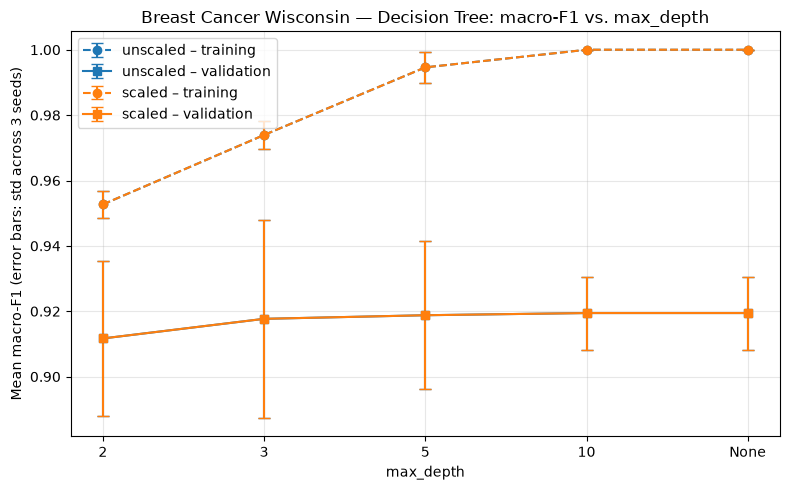

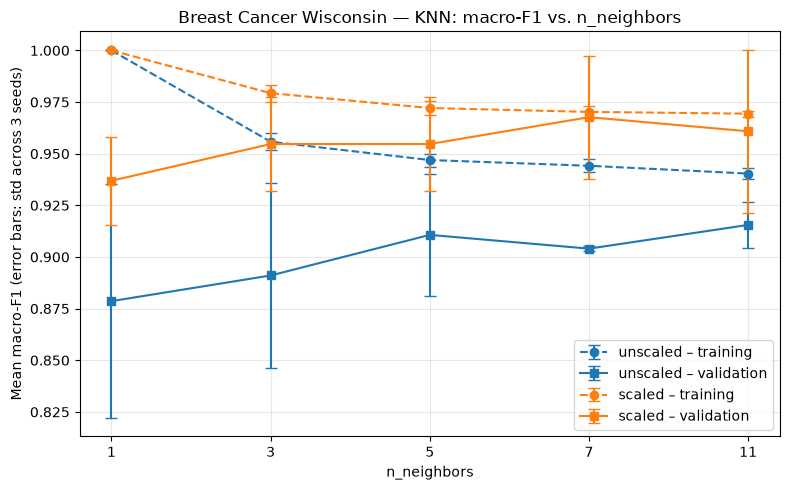

In [24]:
def plot_parameter_comparison(algorithm, param_order, param_label, file_name, plot_title):
    fig, ax = plt.subplots(figsize=(8, 5))
    x_positions = np.arange(len(param_order))
    styles = {"unscaled": "tab:blue", "scaled": "tab:orange"}
    for representation in REPRESENTATIONS:
        part = (summary[(summary["algorithm"] == algorithm) & (summary["representation"] == representation)]
                .set_index("param_value").loc[param_order])
        ax.errorbar(x_positions, part["train_macro_f1_mean"], yerr=part["train_macro_f1_std"],
                    marker="o", linestyle="--", capsize=4, color=styles[representation],
                    label=f"{representation} – training")
        ax.errorbar(x_positions, part["val_macro_f1_mean"], yerr=part["val_macro_f1_std"],
                    marker="s", linestyle="-", capsize=4, color=styles[representation],
                    label=f"{representation} – validation")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(param_order)
    ax.set(xlabel=param_label, ylabel="Mean macro-F1 (error bars: std across 3 seeds)", title=plot_title)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(figure_dir / file_name, dpi=150)
    plt.show()


plot_parameter_comparison("decision_tree", [str(d) for d in DEPTHS], "max_depth",
                          "decision_tree_depth_comparison.png",
                          "Breast Cancer Wisconsin — Decision Tree: macro-F1 vs. max_depth")
plot_parameter_comparison("knn", [str(k) for k in NEIGHBORS], "n_neighbors",
                          "knn_neighbors_comparison.png",
                          "Breast Cancer Wisconsin — KNN: macro-F1 vs. n_neighbors")

**Interpretation (8.2).**

- **Selected configuration:** `breast_cancer_knn_scaled_k7` has the highest mean validation macro-F1 (0.9677 ± 0.0297) and mean validation accuracy 0.9708.
- **Scaling effect:** KNN is the algorithm most affected by scaling. Mean validation macro-F1 rises from 0.8786 to 0.9369 for k = 1, from 0.8910 to 0.9547 for k = 3 and from 0.9040 to 0.9677 for k = 7. Without scaling, large-valued features such as the area features dominate the Euclidean distance. Decision Tree results are identical for both representations, because scaling does not change the order of the values in a feature, so the tree finds the same splits. Gaussian Naive Bayes changes only slightly.
- **Tree depth:** training macro-F1 increases with depth and reaches 1.0 at depth 10 and None. Mean validation macro-F1 increases only from 0.9117 (depth 2) to 0.9195 (depth 10/None), so the train–validation gap widens from 0.041 to 0.081: deeper trees mostly memorise the training data.
- **Neighbour count:** k = 1 always has training macro-F1 = 1.0 and the largest gap. Larger k values reduce the gap; on scaled data validation macro-F1 improves from 0.9369 (k = 1) to 0.9677 (k = 7) and then slightly decreases to 0.9608 (k = 11), so a larger k is not always better.
- **Variability across seeds:** standard deviations of validation macro-F1 range from about 0.001 to 0.057. With only 57 validation samples, one additional error changes accuracy by about 1.8 percentage points, so differences between the top configurations are small relative to this variability.

# 9. Evaluating the Selected Model on the Test Set
## 9.1 Final performance metrics

In [25]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

selected_row = summary.loc[summary["config_id"] == selected_config_id].iloc[0]
selected_representation = selected_row["representation"]
selected_model = fitted_models_seed42[selected_config_id]         
X_test_selected = test_representations[selected_representation]

test_metrics = evaluate(selected_model, X_test_selected, y_test)
y_test_pred = selected_model.predict(X_test_selected)
y_test_proba = selected_model.predict_proba(X_test_selected)

classifier_test = pd.DataFrame([{
    "dataset": DATASET_NAME,
    "selected_configuration": selected_config_id,
    "evaluation_seed": TEST_SEED,
    "val_macro_f1_mean": selected_row["val_macro_f1_mean"],
    "val_macro_f1_std": selected_row["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"],
}])
classifier_test.to_csv(results_dir / f"{DATASET_NAME}_classifier_test.csv", index=False)
print("Breast Cancer Wisconsin — final test evaluation (seed 42)")
display(classifier_test.round(4))
print("Undefined precision classes before zero_division:", test_metrics["undefined_precision_classes"] or "none")
print("Undefined recall classes before zero_division:", test_metrics["undefined_recall_classes"] or "none")

Breast Cancer Wisconsin — final test evaluation (seed 42)


,dataset,selected_configuration,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888


Undefined precision classes before zero_division: none
Undefined recall classes before zero_division: none


**Interpretation (9.1).** The selected `breast_cancer_knn_scaled_k7` model reaches test accuracy 0.9737, macro-F1 0.9713 and ROC-AUC 0.9888. This is within the range seen on validation (0.9677 ± 0.0297), so the validation-based selection was not overly optimistic.

In [26]:
class_names = [str(dataset.target_names[label]) for label in class_labels]
print("Breast Cancer Wisconsin — test classification report:", selected_config_id)
print(classification_report(y_test, y_test_pred, labels=class_labels,
                            target_names=class_names, digits=4, zero_division=0))
report_df = pd.DataFrame(classification_report(
    y_test, y_test_pred, labels=class_labels, target_names=class_names,
    output_dict=True, zero_division=0)).T

Breast Cancer Wisconsin — test classification report: breast_cancer_knn_scaled_k7
              precision    recall  f1-score   support

   malignant     1.0000    0.9286    0.9630        42
      benign     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



## 9.2 Confusion matrix

,Predicted malignant,Predicted benign
Actual malignant,39,3
Actual benign,0,72


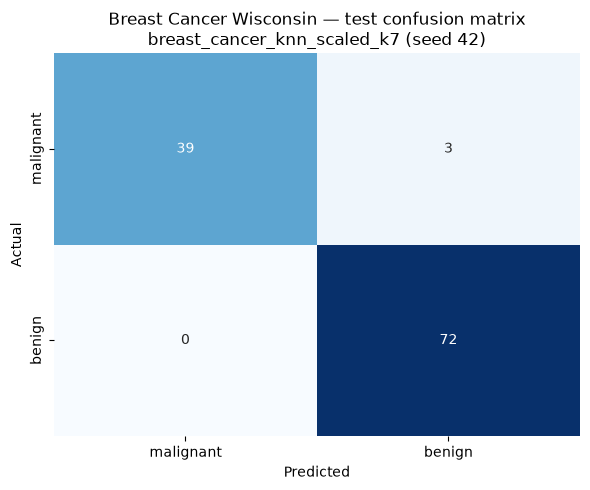

In [27]:
cm = confusion_matrix(y_test, y_test_pred, labels=class_labels)
cm_df = pd.DataFrame(cm,
                     index=[f"Actual {n}" for n in class_names],
                     columns=[f"Predicted {n}" for n in class_names])
display(cm_df)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set(xlabel="Predicted", ylabel="Actual",
       title=f"Breast Cancer Wisconsin — test confusion matrix\n{selected_config_id} (seed 42)")
fig.tight_layout()
fig.savefig(figure_dir / "confusion_matrix_test.png", dpi=150)
plt.show()

In [28]:
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]
print(f"TP={TP}, FN={FN}, FP={FP}, TN={TN}")

precision_manual = TP / (TP + FP) if (TP + FP) > 0 else float("nan")
recall_manual = TP / (TP + FN) if (TP + FN) > 0 else float("nan")
f1_manual = (2 * precision_manual * recall_manual / (precision_manual + recall_manual)
             if (precision_manual + recall_manual) > 0 else float("nan"))

print(f"Malignant precision = TP / (TP + FP) = {TP} / ({TP} + {FP}) = {precision_manual:.4f}")
print(f"Malignant recall    = TP / (TP + FN) = {TP} / ({TP} + {FN}) = {recall_manual:.4f}")
print(f"Malignant F1        = 2·P·R / (P + R) = {f1_manual:.4f}")

manual_check = pd.DataFrame({
    "manual": [precision_manual, recall_manual, f1_manual],
    "classification_report (malignant row)": report_df.loc["malignant", ["precision", "recall", "f1-score"]].to_numpy(),
}, index=["precision", "recall", "f1"]).astype(float)
manual_check["match"] = np.isclose(manual_check.iloc[:, 0], manual_check.iloc[:, 1])
display(manual_check.round(4))

TP=39, FN=3, FP=0, TN=72
Malignant precision = TP / (TP + FP) = 39 / (39 + 0) = 1.0000
Malignant recall    = TP / (TP + FN) = 39 / (39 + 3) = 0.9286
Malignant F1        = 2·P·R / (P + R) = 0.9630


,manual,classification_report (malignant row),match
precision,1.0000,1.0000,True
recall,0.9286,0.9286,True
f1,0.9630,0.9630,True


**Interpretation (9.2).** With class order [0, 1] = [malignant, benign] and rows = actual, columns = predicted, the matrix layout is [[TP, FN], [FP, TN]], Here **TP = 39** malignant tumours were correctly detected, **FN = 3** malignant tumours were predicted as benign, **FP = 0** benign tumours were predicted as malignant and **TN = 72** benign tumours were correctly classified. The manual malignant precision (1.0000), recall (0.9286) and F1 (0.9630) exactly match the *malignant* row of the classification report.

## 9.3 ROC curve

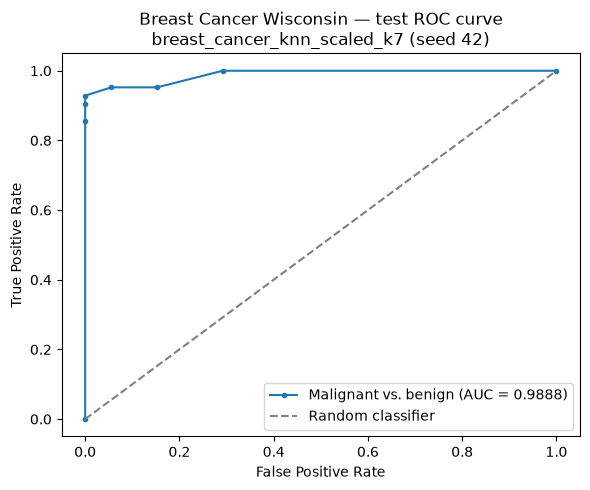

Test ROC-AUC (malignant positive): 0.9888


In [29]:
malignant_column = list(selected_model.classes_).index(0)
y_test_binary = (y_test == 0).astype(int)
fpr, tpr, thresholds = roc_curve(y_test_binary, y_test_proba[:, malignant_column])
test_auc = roc_auc_score(y_test_binary, y_test_proba[:, malignant_column])

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, marker=".", label=f"Malignant vs. benign (AUC = {test_auc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random classifier")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
       title=f"Breast Cancer Wisconsin — test ROC curve\n{selected_config_id} (seed 42)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(figure_dir / "roc_curve_test.png", dpi=150)
plt.show()
print("Test ROC-AUC (malignant positive):", round(test_auc, 4))

**Decision threshold.** Lowering the threshold for the malignant class gives fewer false negatives but more false positives; raising it does the opposite. Each point on the ROC curve corresponds to one threshold; the curve shows this trade-off between the true positive rate and the false positive rate.

## 9.4 Error interpretation

In [30]:
misclassified = pd.DataFrame({
    "row_index": X_test.index,
    "actual": [class_names[class_labels.index(v)] for v in y_test],
    "predicted": [class_names[class_labels.index(v)] for v in y_test_pred],
})
for column, name in enumerate(class_names):
    misclassified[f"P({name})"] = y_test_proba[:, column].round(3)
misclassified = misclassified[misclassified["actual"] != misclassified["predicted"]]
print("Number of misclassified test samples:", len(misclassified), "of", len(y_test))
display(misclassified)

Number of misclassified test samples: 3 of 114


,row_index,actual,predicted,P(malignant),P(benign)
35,41,malignant,benign,0.429,0.571
53,73,malignant,benign,0.143,0.857
84,205,malignant,benign,0.143,0.857


**Interpretation (9.3–9.4).** The malignant-vs-benign ROC-AUC on the test set is 0.9888, so the model ranks almost all malignant tumours above benign ones by predicted probability.

**Example error:** test row 41 is malignant but was predicted benign (P(malignant) = 0.429, i.e. 3 of its 7 nearest neighbours were malignant), so it lies close to the decision boundary. All three errors are false negatives, which is the more serious error type because a cancer case is missed.

**Limitation:** the validation subsets are small (57 samples) and the test result comes from a single seed (42).

# 10. K-Means Clustering

## 10.1 Fit the clustering model

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

N_CLUSTERS = 2


def safe_silhouette(features, cluster_labels):
    n_found = len(np.unique(cluster_labels))
    if n_found < 2 or n_found >= len(cluster_labels):
        return np.nan
    return silhouette_score(features, cluster_labels)


kmeans_records = []
kmeans_models_seed42 = {}

for seed in SEEDS:
    for representation in REPRESENTATIONS:
        X_train_rep = representations[seed][representation]["X_train"]
        X_val_rep = representations[seed][representation]["X_val"]
        y_val_seed = representations[seed]["y_val"]

        kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        kmeans.fit(X_train_rep)                         # no labels are passed
        val_clusters = kmeans.predict(X_val_rep)
        val_silhouette = safe_silhouette(X_val_rep, val_clusters)

        kmeans_records.append({
            "dataset": DATASET_NAME,
            "run_id": f"{DATASET_NAME}_kmeans_{representation}_k{N_CLUSTERS}_s{seed}",
            "seed": seed,
            "representation": representation,
            "n_clusters": N_CLUSTERS,
            "n_init": 10,
            "train_inertia": kmeans.inertia_,
            "val_ari": adjusted_rand_score(y_val_seed, val_clusters),
            "val_silhouette": val_silhouette,
            "val_silhouette_defined": not np.isnan(val_silhouette),
            "val_cluster_counts": str(np.bincount(val_clusters, minlength=N_CLUSTERS).tolist()),
        })
        if seed == TEST_SEED:
            kmeans_models_seed42[representation] = kmeans

kmeans_runs = pd.DataFrame(kmeans_records)
kmeans_runs.to_csv(results_dir / f"{DATASET_NAME}_kmeans_runs.csv", index=False)
print("Breast Cancer Wisconsin — K-Means run table ({} fits)".format(len(kmeans_runs)))
display(kmeans_runs.round(4))

Breast Cancer Wisconsin — K-Means run table (6 fits)


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,val_silhouette_defined,val_cluster_counts
0,breast_cancer,breast_cancer_kmeans_unscaled_k2_s42,42,unscaled,2,10,5.156538e+07,0.3995,0.6387,True,"[46, 11]"
1,breast_cancer,breast_cancer_kmeans_scaled_k2_s42,42,scaled,2,10,7.918810e+03,0.4516,0.2854,True,"[43, 14]"
2,breast_cancer,breast_cancer_kmeans_unscaled_k2_s52,52,unscaled,2,10,4.919078e+07,0.6122,0.6975,True,"[42, 15]"
3,breast_cancer,breast_cancer_kmeans_scaled_k2_s52,52,scaled,2,10,8.003001e+03,0.5586,0.3750,True,"[18, 39]"
4,breast_cancer,breast_cancer_kmeans_unscaled_k2_s62,62,unscaled,2,10,5.305649e+07,0.5013,0.6958,True,"[44, 13]"
5,breast_cancer,breast_cancer_kmeans_scaled_k2_s62,62,scaled,2,10,7.922515e+03,0.7336,0.2758,True,"[36, 21]"


In [32]:
kmeans_summary = kmeans_runs.groupby("representation", sort=False).agg(
    n_runs=("run_id", "size"),
    train_inertia_mean=("train_inertia", "mean"),
    train_inertia_std=("train_inertia", lambda s: s.std(ddof=1)),
    val_ari_mean=("val_ari", "mean"),
    val_ari_std=("val_ari", lambda s: s.std(ddof=1)),
    val_silhouette_mean=("val_silhouette", "mean"),
    val_silhouette_std=("val_silhouette", lambda s: s.std(ddof=1)),
    val_silhouette_valid_seeds=("val_silhouette_defined", "sum"),
).reset_index()
kmeans_summary.insert(0, "dataset", DATASET_NAME)
kmeans_summary.to_csv(results_dir / f"{DATASET_NAME}_kmeans_summary.csv", index=False)
print("Breast Cancer Wisconsin — K-Means summary across 3 seeds")
display(kmeans_summary.round(4))

Breast Cancer Wisconsin — K-Means summary across 3 seeds


,dataset,representation,n_runs,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_seeds
0,breast_cancer,unscaled,3,5.127088e+07,1.949607e+06,0.5043,0.1064,0.6773,0.0334,3
1,breast_cancer,scaled,3,7.948109e+03,4.757430e+01,0.5813,0.1424,0.3121,0.0547,3


**Interpretation (10.1).** Scaling generally improves alignment with the true classes; however, results may vary between different trials.
On the other hand, while the cluster quality score might appear high for unscaled data, this is misleading. This occurs because features with large values ​​dominate the calculations, causing the clusters to appear as though they are separated along only a single dimension. Therefore, a high score does not prove that an unscaled model is actually better.

## 10.2 Final cluster evaluation on the fixed test set

In [33]:
kmeans_test_records = []
test_cluster_predictions = {}

for representation in REPRESENTATIONS:
    kmeans = kmeans_models_seed42[representation]
    X_test_rep = test_representations[representation]
    test_clusters = kmeans.predict(X_test_rep)
    test_cluster_predictions[representation] = test_clusters

    counts = np.bincount(test_clusters, minlength=N_CLUSTERS)
    test_silhouette = safe_silhouette(X_test_rep, test_clusters)
    kmeans_test_records.append({
        "dataset": DATASET_NAME,
        "representation": representation,
        "evaluation_seed": TEST_SEED,
        "n_test": len(y_test),
        **{f"cluster_{c}_count": int(counts[c]) for c in range(N_CLUSTERS)},
        "test_ari": adjusted_rand_score(y_test, test_clusters),
        "test_silhouette": test_silhouette if not np.isnan(test_silhouette) else "N/A",
    })

    contingency = pd.crosstab(
        pd.Series([class_names[class_labels.index(v)] for v in y_test], name="Actual class"),
        pd.Series(test_clusters, name="Predicted cluster"),
    )
    print(f"Breast Cancer Wisconsin — class vs. cluster contingency table ({representation}, seed 42, test set)")
    display(contingency)

kmeans_test = pd.DataFrame(kmeans_test_records)
kmeans_test.to_csv(results_dir / f"{DATASET_NAME}_kmeans_test.csv", index=False)
print("Breast Cancer Wisconsin — K-Means final test evaluation")
display(kmeans_test.round(4))

Breast Cancer Wisconsin — class vs. cluster contingency table (unscaled, seed 42, test set)


Predicted cluster,0,1
Actual class,,
benign,72,0
malignant,14,28


Breast Cancer Wisconsin — class vs. cluster contingency table (scaled, seed 42, test set)


Predicted cluster,0,1
Actual class,,
benign,69,3
malignant,5,37


Breast Cancer Wisconsin — K-Means final test evaluation


,dataset,representation,evaluation_seed,n_test,cluster_0_count,cluster_1_count,test_ari,test_silhouette
0,breast_cancer,unscaled,42,114,86,28,0.5585,0.7120
1,breast_cancer,scaled,42,114,74,40,0.7354,0.3251


## 10.3 Visualise and interpret the clusters

Seed-42 training data


,worst radius,worst concave points
malignant,21.144,0.186
benign,13.319,0.073


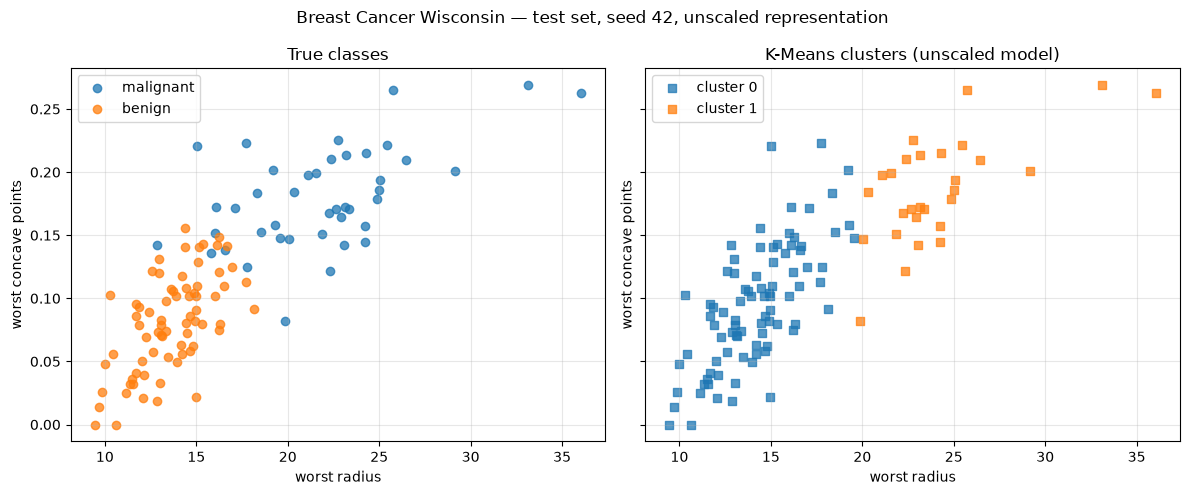

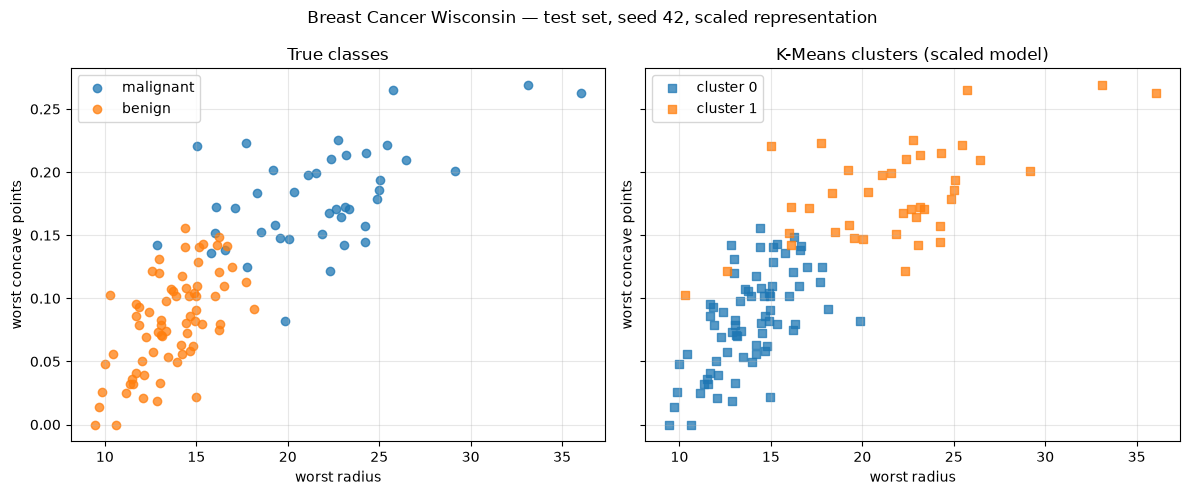

In [34]:
plot_features = ["worst radius", "worst concave points"]

training_class_means = (splits[TEST_SEED]["X_train"][plot_features]
                        .groupby(splits[TEST_SEED]["y_train"]).mean())
training_class_means.index = [class_names[class_labels.index(v)] for v in training_class_means.index]
print("Seed-42 training data")
display(training_class_means.round(3))

for representation in REPRESENTATIONS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    x_values = X_test[plot_features[0]]
    y_values = X_test[plot_features[1]]

    for label in class_labels:
        mask = (y_test == label).to_numpy()
        axes[0].scatter(x_values[mask], y_values[mask], label=class_names[class_labels.index(label)], alpha=0.75)
    axes[0].set_title("True classes")

    clusters = test_cluster_predictions[representation]
    for cluster_id in range(N_CLUSTERS):
        mask = clusters == cluster_id
        axes[1].scatter(x_values[mask], y_values[mask], label=f"cluster {cluster_id}", alpha=0.75, marker="s")
    axes[1].set_title(f"K-Means clusters ({representation} model)")

    for ax in axes:
        ax.set(xlabel=plot_features[0], ylabel=plot_features[1])
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(f"Breast Cancer Wisconsin — test set, seed 42, {representation} representation ")
    fig.tight_layout()
    fig.savefig(figure_dir / f"kmeans_{representation}_test_clusters.png", dpi=150)
    plt.show()

**Interpretation (10.2–10.3).**

- **Unscaled (test ARI 0.559):** cluster 1 contains only malignant tumours (28), while cluster 0 contains all 72 benign tumours together with 14 malignant ones. Because the area features dominate the distances, K-Means mainly separates large tumours from smaller ones, and smaller malignant tumours are mixed with the benign group.
- **Scaled (test ARI 0.735):** cluster 0 contains 69 benign and 5 malignant samples, cluster 1 contains 37 malignant and 3 benign samples. After scaling, all features contribute to the distance and the partition is much closer to the true classes. The test silhouette is again higher for unscaled features (0.712 vs. 0.325), for the same feature-space reason as above.
- The plots use `worst radius` and `worst concave points` (malignant training means 21.1 and 0.186 vs. benign 13.3 and 0.073). 
- **Information available during fitting:** the three classifiers were trained with the true labels `y_train`, so they learn which side of a boundary each class belongs to. K-Means received only the features, so the labels were used only afterwards for evaluation.

# 12. Run inventory and combined result files

In [35]:
print(f"{DATASET_NAME}: classifier fits = {len(runs)}, K-Means fits = {len(kmeans_runs)}, "
      f"total model fits = {len(runs) + len(kmeans_runs)}")
assert len(runs) == 66 and len(kmeans_runs) == 6 and len(summary) == 22

expected_rows = {"classifier_runs": 132, "classifier_summary": 44, "classifier_test": 2,
                 "kmeans_runs": 12, "kmeans_summary": 4, "kmeans_test": 4}
datasets = ["breast_cancer", "wine"]
if all((results_dir / f"{d}_{name}.csv").exists() for d in datasets for name in expected_rows):
    inventory = []
    for name, n_expected in expected_rows.items():
        combined = pd.concat([pd.read_csv(results_dir / f"{d}_{name}.csv") for d in datasets],
                             ignore_index=True)
        combined.to_csv(f"{name}.csv", index=False)
        inventory.append({"file": f"{name}.csv", "rows": len(combined), "required_rows": n_expected,
                          "ok": len(combined) == n_expected})
    display(pd.DataFrame(inventory))
else:
    print("Run the other notebook as well to create the combined CSV files.")

breast_cancer: classifier fits = 66, K-Means fits = 6, total model fits = 72


,file,rows,required_rows,ok
0,classifier_runs.csv,132,132,True
1,classifier_summary.csv,44,44,True
2,classifier_test.csv,2,2,True
3,kmeans_runs.csv,12,12,True
4,kmeans_summary.csv,4,4,True
5,kmeans_test.csv,4,4,True
